# 02 · Nonlinear MPC

Nonlinear MPC with `parampc.OCP` (the problem) and `parampc.NMPC` (the controller), on two problems:

- **Quadrotor with a slung load.** A planar quadrotor carries a load on a 0.6 m cable and has to follow a
  sinusoidal path with the **load swing below 10°** (soft) and each rotor's **thrust in [0, 9] N** (hard).
  Nonlinear and underactuated: 8 states, 2 thrusts.
- **Cart-pole swing-up.** The pole starts hanging and must be swung up and balanced, with a **non-convex cost**
  $1-\cos\theta$, a force limit and a track limit.

`NMPC` runs sequential quadratic programming. Each iteration linearizes the dynamics and constraints along the
current guess (JAX derivatives), expands the cost to second order with a Levenberg–Marquardt term, and solves the
resulting linear MPC QP with `solve_qp`: the same interior-point method as notebook 01, warm-started with the
previous multipliers. A backtracking line search on an $\ell_1$ merit function picks the step. `sqp_iters=1` is
the real-time iteration. A whole closed loop runs as one compiled `lax.scan`, and `jax.vmap` batches closed loops.

Both problems are defined in `parampc.models`, the same definitions the examples, tests and benchmark use.

## 0. Import Dependencies

In [1]:
import contextlib
import inspect
import io
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import parampc as pm
from parampc.models import cartpole, quadrotor as quad

print(f"parampc {pm.__version__} | jax {jax.__version__} | devices {jax.devices()} | backends {pm.available_backends()}")

parampc 0.1.0 | jax 0.11.1 | devices [CudaDevice(id=0)] | backends ['cuda', 'scan', 'sweep']


## 1. Parameter Declaration

**Quadrotor.** Horizon $N = 30$ (1.5 s at $\Delta t = 0.05$ s).
- Open loop: SQP from the hover initial guess for 40 iterations, compared with the converged optimum, cost
  **277.4224**, which acados reproduces independently (SQP with merit backtracking).
- Closed loop: 400 steps (20 s), 3 SQP iterations per step, a 1.8 N lateral wind gust for $8 \le t < 12$ s and
  $10^{-3}$ state noise. The plant is integrated with RK4 (5 substeps), not with the controller's one-step
  midpoint model, so the controller never sees its own model.

**Cart-pole.** Horizon $N = 60$ (3 s), 3 SQP iterations per step, 160 steps (8 s); then 32 swing-ups from initial
angles within $\pm0.6$ rad of hanging, solved together as one batch.

In [2]:
BACKEND = 'auto'

N = 30                        # quadrotor horizon
OPEN_LOOP_SQP = 40            # SQP iterations of the open-loop convergence study
REF_COST = 277.4224           # the converged optimum at t = 0 (reproduced by acados)
STEPS = 400                   # closed loop: 20 s

N_CP, STEPS_CP = 60, 160      # cart-pole horizon and closed-loop steps
MONTE_CARLO = 32              # cart-pole swing-ups solved as one batch

print(f"quadrotor: masses {quad.M_QUAD} kg + load {quad.M_LOAD} kg, cable {quad.L_CABLE} m, dt {quad.DT} s; "
      f"thrust in [0, {quad.T_MAX}] N (hard), |phi| <= {np.rad2deg(quad.PHI_MAX):.0f} deg and "
      f"|phi'| <= {quad.PHID_MAX} rad/s (soft, l1 penalty {quad.SOFT_L1:.0f})")
print(f"           Q = diag{np.asarray(quad.Q_DIAG).tolist()}, Q_N = 5 Q, R = diag{np.asarray(quad.R_DIAG).tolist()}; "
      f"controller {quad.NMPC_OPTIONS}")
print(f"cart-pole: |force| <= {cartpole.U_MAX} N, |cart| <= {cartpole.X_MAX} m; controller {cartpole.NMPC_OPTIONS}")

quadrotor: masses 1.0 kg + load 0.25 kg, cable 0.6 m, dt 0.05 s; thrust in [0, 9.0] N (hard), |phi| <= 10 deg and |phi'| <= 1.2 rad/s (soft, l1 penalty 5000)
           Q = diag[60.0, 60.0, 1.0, 5.0, 2.0, 2.0, 0.5, 0.5], Q_N = 5 Q, R = diag[0.02, 0.02]; controller {'sqp_iters': 3, 'lm': 0.5, 'merit_weight': 500.0, 'qp_tol': 1e-06, 'hessian': 'exact'}
cart-pole: |force| <= 15.0 N, |cart| <= 1.5 m; controller {'sqp_iters': 3, 'lm': 0.1}


## 2. The Problems

An `OCP` holds the discrete-time dynamics $x_{t+1} = F(x_t, u_t, p_t)$ (here the explicit midpoint rule or RK4
applied to continuous-time dynamics, `pm.midpoint` / `pm.rk4`), the stage and terminal costs, constraints
$g(x, u, p) \le 0$, input and state bounds, and groups of constraints made soft by a shared slack. `p_t` are
per-stage parameters; the quadrotor's are its reference trajectory. The definitions:

In [3]:
print(inspect.getsource(quad.ocp))
print(inspect.getsource(cartpole.ocp))

def ocp(N=30):
    """The tracking NMPC problem: params p_t = horizon_reference(...)[t]; hard thrust bounds; |phi| and |phi'| soft,
    one slack per pair of rows; hover thrust as the initial guess (zero thrust would free-fall)."""
    return OCP(
        nx=NX, nu=NU, N=N,
        dynamics=midpoint(lambda x, u, p: dynamics(x, u), DT),
        stage_cost=lambda x, u, p: 0.5 * jnp.sum(Q_DIAG * (x - p) ** 2) + 0.5 * jnp.sum(R_DIAG * (u - U_HOVER) ** 2),
        terminal_cost=lambda x, p: 0.5 * jnp.sum(Q_TERM * (x - p) ** 2),
        u_min=0.0, u_max=T_MAX,
        constraints=lambda x, u, p: jnp.array([x[3] - PHI_MAX, -x[3] - PHI_MAX, x[7] - PHID_MAX, -x[7] - PHID_MAX]),
        soft=[[0, 1], [2, 3]], soft_l1=SOFT_L1, soft_l2=SOFT_L2, u_guess=U_HOVER)

def ocp(N=60, dt=DT):
    """The swing-up problem: RK4 prediction model, terminal cost 10 x the state cost, force and track limits."""
    return OCP(nx=4, nu=1, N=N, dynamics=rk4(dynamics, dt),
               stage_cost=lambda x, u, p: st

## 3. Simulation Loop

**3a. Quadrotor, open loop.** From the hover initial guess at $t = 0$, one SQP iteration at a time (a controller
with `sqp_iters=1`; the multipliers carry over between calls). Recorded: the cost, the multiple-shooting defect
$\sum_t\|x_{t+1} - F(x_t, u_t)\|_1$ (how far the plan is from being dynamically consistent) and the worst
constraint violation.

**3b. Quadrotor, closed loop.** `NMPC.closed_loop` runs all 400 steps inside one `lax.scan`. The first call
includes compilation, so it is timed separately.

**3c. Cart-pole.** The swing-up with the default `hessian='convexify'`, which lifts the negative curvature of
$1-\cos\theta$ so that every QP is convex, and with `hessian='exact'`.

**3d. Cart-pole batch.** 32 swing-ups as one `jax.vmap`: each MPC step solves the 32 SQP subproblems together.

In [4]:
# ---- 3a. quadrotor, open loop: SQP convergence at t = 0
ocp = quad.ocp(N)
x0, SR = quad.initial_state(), quad.horizon_reference(0.0, N)
one_iteration = pm.NMPC(ocp, backend=BACKEND, **dict(quad.NMPC_OPTIONS, sqp_iters=1))
F = jax.vmap(lambda x, u: ocp.dynamics(x, u, None))


def defect(X, U):
    return float(jnp.sum(jnp.abs(X[1:] - F(X[:-1], U[:, :quad.NU]))))


def violation(X, U):
    """Worst violation of the QP's rows: soft swing limits (with their slacks) and slacks >= 0."""
    phi, phid, s_phi, s_rate = X[:-1, 3], X[:-1, 7], U[:, 2], U[:, 3]
    rows = jnp.stack([jnp.abs(phi) - quad.PHI_MAX - s_phi, jnp.abs(phid) - quad.PHID_MAX - s_rate, -s_phi, -s_rate])
    return float(jnp.maximum(jnp.max(rows), 0.0))


state = one_iteration.init(x0, SR)
history = []
for k in range(OPEN_LOOP_SQP):
    state, info = one_iteration.solve(state, x0, SR)
    history.append((float(info['cost']), defect(state.X, state.U), violation(state.X, state.U)))
history = np.array(history)
X_plan, U_plan = np.asarray(state.X), np.asarray(state.U)

# ---- 3b. quadrotor, closed loop: 20 s with a wind gust and sensor noise
ctrl = pm.NMPC(ocp, backend=BACKEND, **quad.NMPC_OPTIONS)
plant = quad.plant(STEPS)                              # RK4 plant, wind gust from 8 to 12 s, noise
params_fn = lambda k: quad.horizon_reference(k * quad.DT, N)
t0 = time.perf_counter()
jax.block_until_ready(ctrl.closed_loop(plant, x0, STEPS, params_fn=params_fn))
t_first = time.perf_counter() - t0
t0 = time.perf_counter()
xs, us, infos = jax.block_until_ready(ctrl.closed_loop(plant, x0, STEPS, params_fn=params_fn))
t_run = time.perf_counter() - t0
xs, us, refs = np.asarray(xs), np.asarray(us), np.asarray(jax.vmap(lambda k: quad.reference(k * quad.DT)[:2])(jnp.arange(STEPS)))
t = np.arange(STEPS) * quad.DT

# ---- 3c. cart-pole swing-up, convexified and exact Hessians. With the exact Hessian the QPs are non-convex and
# the IPM reports non-finite Newton steps; its messages are captured and counted.
cp_plant, cp_x0 = cartpole.plant(), cartpole.hanging()
swingups, breakdowns = {}, {}
for hessian in ('convexify', 'exact'):
    messages = io.StringIO()
    with contextlib.redirect_stdout(messages):
        cp = pm.NMPC(cartpole.ocp(N_CP), backend=BACKEND, hessian=hessian, **cartpole.NMPC_OPTIONS)
        st = cp.init(cp_x0)                            # u = 0 rolled out: the pole hangs
        for _ in range(10):                            # 30 SQP iterations for the first plan
            st, _ = cp.solve(st, cp_x0)
        jax.block_until_ready(cp.closed_loop(cp_plant, cp_x0, STEPS_CP, state=st))
        t0 = time.perf_counter()
        out = jax.block_until_ready(cp.closed_loop(cp_plant, cp_x0, STEPS_CP, state=st))
        swingups[hessian] = [np.asarray(out[0]), np.asarray(out[1]), out[2], (time.perf_counter() - t0) / STEPS_CP]
        jax.effects_barrier()
    breakdowns[hessian] = messages.getvalue().count('non-finite Newton step')

# ---- 3d. 32 cart-pole swing-ups as one batch
cp = pm.NMPC(cartpole.ocp(N_CP), backend=BACKEND, **cartpole.NMPC_OPTIONS)


def swing_up(x0):
    st = cp.init(x0)
    st = jax.lax.fori_loop(0, 10, lambda i, s: cp.solve(s, x0)[0], st)
    return cp.closed_loop(cp_plant, x0, STEPS_CP, state=st)


angles = jnp.pi + jnp.linspace(-0.6, 0.6, MONTE_CARLO)
mc_x0 = jnp.stack([jnp.zeros(MONTE_CARLO), angles, jnp.zeros(MONTE_CARLO), jnp.zeros(MONTE_CARLO)], axis=1)
batch = jax.jit(jax.vmap(swing_up))
jax.block_until_ready(batch(mc_x0))
t0 = time.perf_counter()
mc_xs, mc_us, _ = jax.block_until_ready(batch(mc_x0))
t_mc = time.perf_counter() - t0
mc_xs, mc_us = np.asarray(mc_xs), np.asarray(mc_us)

## 4. Plotting/Printing Results

In [5]:
print("== 3a. quadrotor, open loop at t = 0: SQP convergence")
print(f"{'SQP it':>7} {'cost':>10} {'cost - optimum':>15} {'defect':>9} {'violation':>10}")
for k in (0, 1, 2, 5, 11, 24, 39):
    c, dfc, vio = history[k]
    print(f"{k + 1:7d} {c:10.4f} {c - REF_COST:15.2e} {dfc:9.1e} {vio:10.1e}")
print(f"max |phi| in the final plan: {np.rad2deg(np.abs(X_plan[:, 3]).max()):.4f} deg (limit 10)")

err = np.linalg.norm(xs[:, :2] - refs, axis=1)
metrics = {
    'tracking RMS [m]': np.sqrt(np.mean(err**2)),
    'tracking RMS after 2 s [m]': np.sqrt(np.mean(err[t >= 2] ** 2)),
    'max tracking error [m]': err.max(),
    'max |phi| [deg]  (soft limit 10)': np.abs(np.rad2deg(xs[:, 3])).max(),
    "max |phi'| [rad/s]  (soft limit 1.2)": np.abs(xs[:, 7]).max(),
    'min thrust [N]  (hard limit 0)': us.min(),
    'max thrust [N]  (hard limit 9)': us.max(),
    'IPM iterations per MPC step (mean)': float(jnp.mean(infos['qp_iters'])),
}
print(f"\n== 3b. quadrotor, closed loop: {STEPS} steps x {quad.NMPC_OPTIONS['sqp_iters']} SQP iterations on "
      f"'{pm.backends.resolve_backend(BACKEND)}'")
print(f"first call (includes compilation) {t_first:.1f} s | run {t_run:.2f} s = {1e3 * t_run / STEPS:.1f} ms per MPC step")
for name, value in metrics.items():
    print(f"   {name:40s} {value:9.4f}")

print("\n== 3c. cart-pole swing-up")
for hessian, (cx, cu, cinfo, cms) in swingups.items():
    th = cartpole.wrap(cx[:, 1])
    up = STEPS_CP - np.argmax(np.abs(th[::-1]) >= 0.1)
    upright = np.abs(th[-20:]).max() < 0.05
    print(f"   hessian={hessian:9s}: {'upright' if upright else 'not upright'} at the end (|theta| < 0.1 from t = "
          f"{up * cartpole.DT:.2f} s)" if upright else f"   hessian={hessian:9s}: never leaves the bottom "
          f"(max |theta - pi| {np.abs(cx[:, 1] - np.pi).max():.3f} rad)", end='')
    print(f"; max |force| {np.abs(cu).max():.2f} N, max |cart| {np.abs(cx[:, 0]).max():.3f} m, {1e3 * cms:.2f} ms per step; "
          f"IPM breakdowns (non-convex QPs): {breakdowns[hessian]}")
mc_th = cartpole.wrap(mc_xs[:, :, 1])
mc_up = np.abs(mc_th[:, -20:]).max(axis=1) < 0.05
print(f"\n== 3d. {MONTE_CARLO} swing-ups as one batch: {int(mc_up.sum())}/{MONTE_CARLO} upright over the last second; "
      f"max |force| {np.abs(mc_us).max():.2f} N, max |cart| {np.abs(mc_xs[:, :, 0]).max():.3f} m; "
      f"{1e3 * t_mc / STEPS_CP:.2f} ms per step for all {MONTE_CARLO}")

assert abs(history[-1, 0] - REF_COST) < 1e-2 and history[-1, 1] < 1e-6 and history[-1, 2] < 1e-9
assert metrics['min thrust [N]  (hard limit 0)'] >= -1e-9 and metrics['max thrust [N]  (hard limit 9)'] <= quad.T_MAX + 1e-9
assert metrics['max |phi| [deg]  (soft limit 10)'] < 10.5
assert np.abs(cartpole.wrap(swingups['convexify'][0][-20:, 1])).max() < 0.05 and mc_up.all()
assert breakdowns['convexify'] == 0
print("\nPASS: SQP converges to the optimum; hard limits hold in closed loop; the swing stays within 5% of its soft "
      "limit; every swing-up ends upright")

== 3a. quadrotor, open loop at t = 0: SQP convergence
 SQP it       cost  cost - optimum    defect  violation
      1   322.6807        4.53e+01   2.0e-01    0.0e+00
      2   286.9285        9.51e+00   1.1e-01    0.0e+00
      3   280.5041        3.08e+00   1.4e-02    0.0e+00
      6   278.0973        6.75e-01   1.1e-03    0.0e+00
     12   277.5454        1.23e-01   5.8e-05    2.0e-12
     25   277.4415        1.91e-02   1.9e-06    6.4e-13
     40   277.4257        3.34e-03   3.0e-07    1.8e-13
max |phi| in the final plan: 10.0000 deg (limit 10)

== 3b. quadrotor, closed loop: 400 steps x 3 SQP iterations on 'cuda'
first call (includes compilation) 5.2 s | run 3.02 s = 7.5 ms per MPC step
   tracking RMS [m]                            0.2141
   tracking RMS after 2 s [m]                  0.1593
   max tracking error [m]                      0.6677
   max |phi| [deg]  (soft limit 10)           10.2096
   max |phi'| [rad/s]  (soft limit 1.2)        0.9220
   min thrust [N]  (hard limit

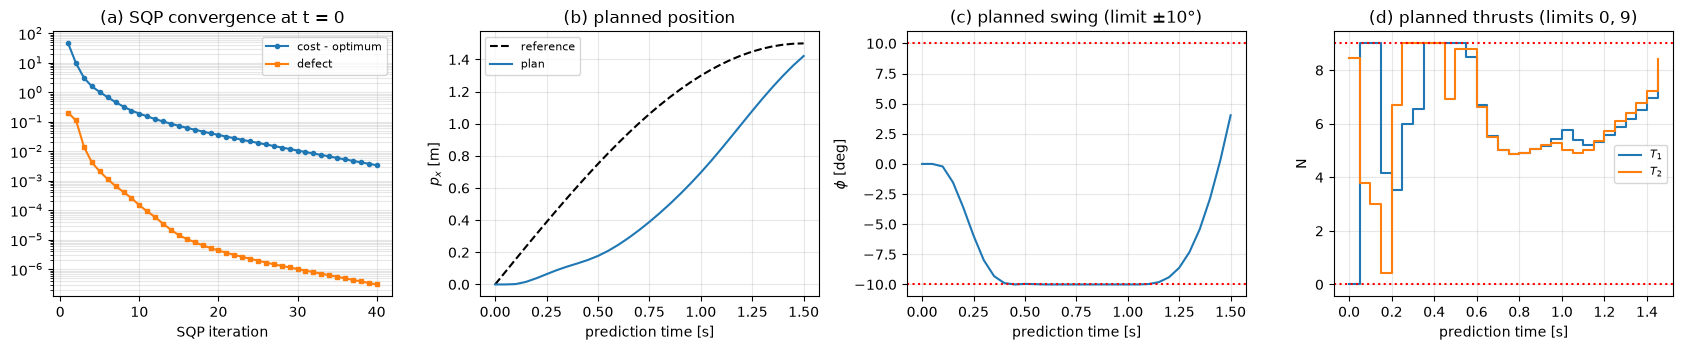

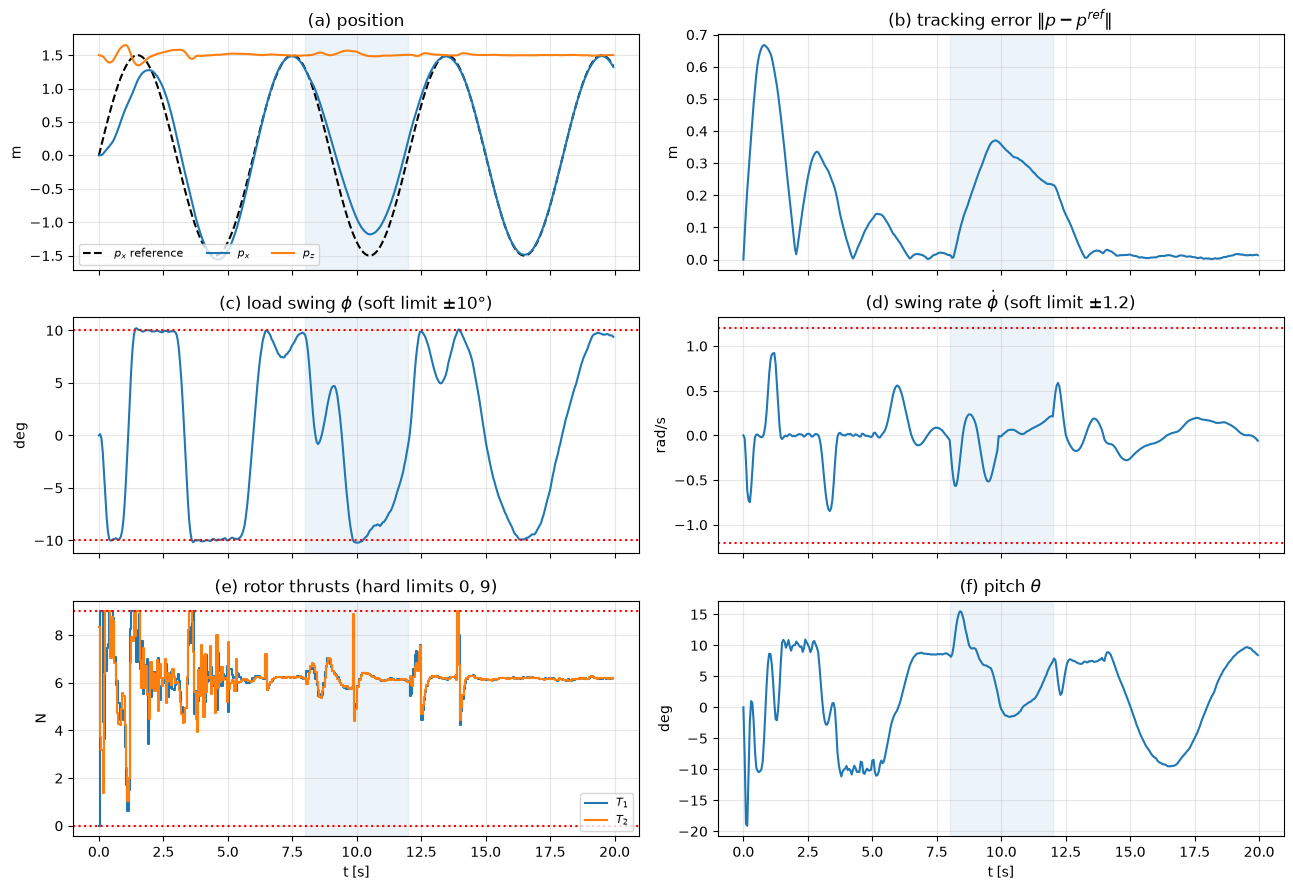

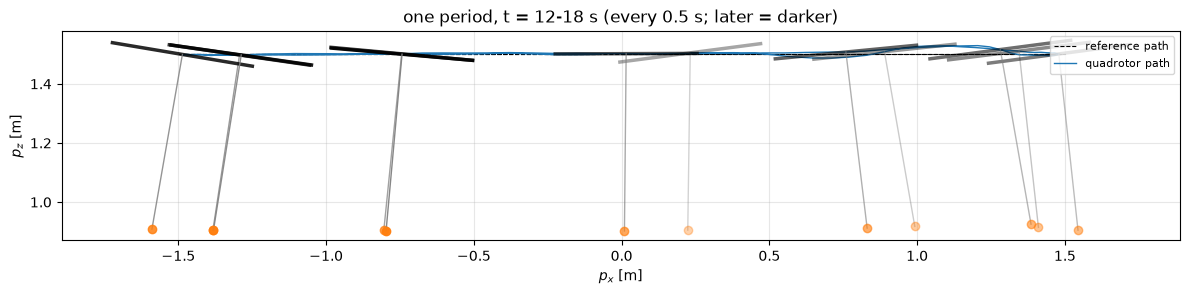

In [6]:
# ---- quadrotor: open-loop convergence and the converged plan
th_ = np.arange(N + 1) * quad.DT
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
its = np.arange(1, OPEN_LOOP_SQP + 1)
ax[0].semilogy(its, history[:, 0] - REF_COST, 'o-', ms=3, label='cost - optimum')
ax[0].semilogy(its, np.maximum(history[:, 1], 1e-16), 's-', ms=3, label='defect')
ax[0].set(xlabel='SQP iteration', title='(a) SQP convergence at t = 0')
ax[0].legend(fontsize=8)
ax[1].plot(th_, np.asarray(SR)[:, 0], 'k--', label='reference')
ax[1].plot(th_, X_plan[:, 0], label='plan')
ax[1].set(xlabel='prediction time [s]', ylabel='$p_x$ [m]', title='(b) planned position')
ax[1].legend(fontsize=8)
ax[2].plot(th_, np.rad2deg(X_plan[:, 3]))
for sgn in (1, -1):
    ax[2].axhline(10 * sgn, color='r', ls=':')
ax[2].set(xlabel='prediction time [s]', ylabel=r'$\phi$ [deg]', title=r'(c) planned swing (limit $\pm10°$)')
ax[3].step(th_[:-1], U_plan[:, 0], where='post', label='$T_1$')
ax[3].step(th_[:-1], U_plan[:, 1], where='post', label='$T_2$')
for b in (0, quad.T_MAX):
    ax[3].axhline(b, color='r', ls=':')
ax[3].set(xlabel='prediction time [s]', ylabel='N', title='(d) planned thrusts (limits 0, 9)')
ax[3].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

# ---- quadrotor: closed loop
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
ax = ax.ravel()
ax[0].plot(t, refs[:, 0], 'k--', label='$p_x$ reference')
ax[0].plot(t, xs[:, 0], label='$p_x$')
ax[0].plot(t, xs[:, 1], label='$p_z$')
ax[0].set(ylabel='m', title='(a) position')
ax[1].plot(t, err)
ax[1].set(ylabel='m', title=r'(b) tracking error $\|p - p^{ref}\|$')
ax[2].plot(t, np.rad2deg(xs[:, 3]))
ax[2].set(ylabel='deg', title=r'(c) load swing $\phi$ (soft limit $\pm10°$)')
ax[3].plot(t, xs[:, 7])
ax[3].set(ylabel='rad/s', title=r"(d) swing rate $\dot\phi$ (soft limit $\pm1.2$)")
ax[4].step(t, us[:, 0], where='post', label='$T_1$')
ax[4].step(t, us[:, 1], where='post', label='$T_2$')
ax[4].set(ylabel='N', xlabel='t [s]', title='(e) rotor thrusts (hard limits 0, 9)')
ax[5].plot(t, np.rad2deg(xs[:, 2]))
ax[5].set(ylabel='deg', xlabel='t [s]', title=r'(f) pitch $\theta$')
for a, lim in ((ax[2], 10), (ax[3], quad.PHID_MAX)):
    a.axhline(lim, color='r', ls=':'); a.axhline(-lim, color='r', ls=':')
for lim in (0, quad.T_MAX):
    ax[4].axhline(lim, color='r', ls=':')
for a in ax:
    a.axvspan(quad.WIND['start'], quad.WIND['end'], color='tab:blue', alpha=0.08)
    a.grid(alpha=0.3)
ax[0].legend(ncol=3, fontsize=8, loc='lower left'); ax[4].legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()


# ---- quadrotor: strobe view of one period after the gust
def draw_quadrotor(ax, s, alpha):
    px, pz, theta, phi = s[:4]
    arm = 1.5 * quad.ARM * np.array([np.cos(theta), np.sin(theta)])       # arms drawn 1.5x for visibility
    load = np.array([px + quad.L_CABLE * np.sin(phi), pz - quad.L_CABLE * np.cos(phi)])
    ax.plot([px - arm[0], px + arm[0]], [pz - arm[1], pz + arm[1]], 'k-', lw=2.5, alpha=alpha)
    ax.plot([px, load[0]], [pz, load[1]], '-', color='gray', lw=1, alpha=alpha)
    ax.plot(*load, 'o', color='tab:orange', ms=6, alpha=alpha)


fig, a = plt.subplots(figsize=(12, 3.8))
window = (t >= 12) & (t < 18)
a.plot(refs[window, 0], np.full(window.sum(), quad.Z_REF), 'k--', lw=0.8, label='reference path')
a.plot(xs[window, 0], xs[window, 1], color='tab:blue', lw=1, label='quadrotor path')
first = np.flatnonzero(window)[0]
for k in np.flatnonzero(window)[::10]:
    draw_quadrotor(a, xs[k], 0.35 + 0.65 * (k - first) / window.sum())
a.set(xlabel='$p_x$ [m]', ylabel='$p_z$ [m]', title='one period, t = 12-18 s (every 0.5 s; later = darker)')
a.set_aspect('equal')
a.grid(alpha=0.3)
a.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

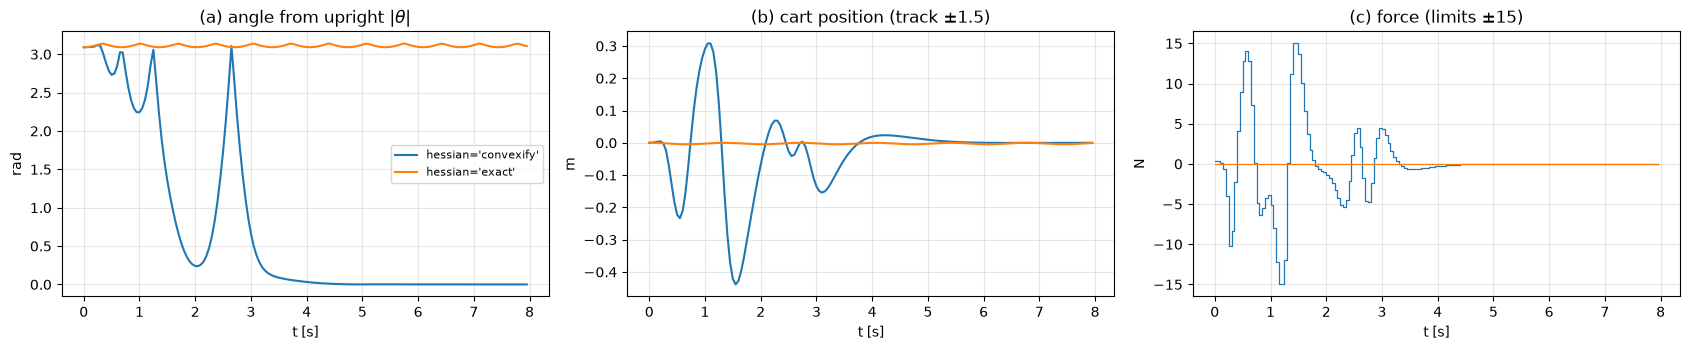

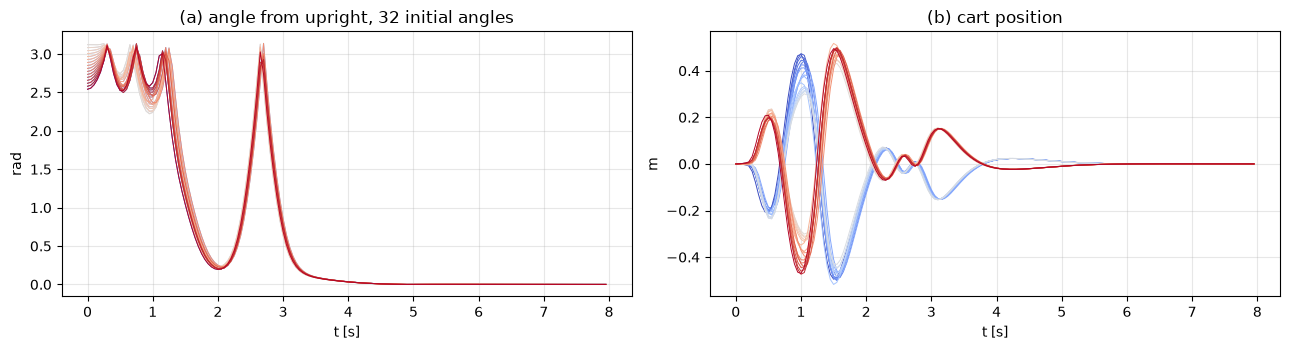

In [7]:
# ---- cart-pole: swing-up (convexified vs exact Hessian) and the batch of 32
tc = cartpole.DT * np.arange(STEPS_CP)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
for hessian, color in (('convexify', 'tab:blue'), ('exact', 'tab:orange')):
    cx, cu = swingups[hessian][:2]
    ax[0].plot(tc, np.abs(cartpole.wrap(cx[:, 1])), color=color, label=f"hessian='{hessian}'")
    ax[1].plot(tc, cx[:, 0], color=color)
    ax[2].step(tc, cu[:, 0], where='post', color=color, lw=0.9)
ax[0].set(xlabel='t [s]', ylabel='rad', title=r'(a) angle from upright $|\theta|$')
ax[0].legend(fontsize=8)
ax[1].set(xlabel='t [s]', ylabel='m', title='(b) cart position (track $\\pm1.5$)')
ax[2].set(xlabel='t [s]', ylabel='N', title='(c) force (limits $\\pm15$)')
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
cmap = plt.get_cmap('coolwarm')
for i in range(MONTE_CARLO):
    ax[0].plot(tc, np.abs(mc_th[i]), color=cmap(i / (MONTE_CARLO - 1)), lw=0.7)
    ax[1].plot(tc, mc_xs[i, :, 0], color=cmap(i / (MONTE_CARLO - 1)), lw=0.7)
ax[0].set(xlabel='t [s]', ylabel='rad', title=f'(a) angle from upright, {MONTE_CARLO} initial angles')
ax[1].set(xlabel='t [s]', ylabel='m', title='(b) cart position')
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Reading the results.**
- *Open loop.* The SQP converges linearly to the optimum; the Levenberg–Marquardt term ($\lambda = 0.5$) trades
  speed for robustness from a poor initial guess. The swing constraint is active at exactly 10°: tracking the
  reference would need more swing than the limit allows.
- *Closed loop.* The hard thrust limits hold exactly because they bound decision variables. The soft swing limit
  is exceeded by about 2%: it constrains the *predicted* trajectory, and the plant (RK4, wind, noise) is not the
  model. The tracking error grows during the gust (shaded) and recovers after it.
- *Non-convex cost.* With the exact Hessian the cart-pole's QPs are non-convex around the hanging position: the
  interior-point method breaks down on them and the pole never leaves the bottom. The convexified Hessian gives
  convex QPs and swings the pole up within a few seconds, from every initial angle of the batch.
- *Not shown here:* closed-loop stability or recursive feasibility. Neither problem has a terminal set, and the
  quadrotor's state constraints are soft.